# Day 19: Tree smellmap - Vienna

Kate McLean-style scent contours from street-tree data: Each fragrant tree gives off a scent cloud scaled by its trunk diameter, coloured by species. Nothing is measured: it's an *imagined* smellscape built from where the trees are.

Uses the **Baumkataster Wien** (Vienna tree register) via the city's open-data WFS: about 200,000 trees with species and trunk **circumference** (cm), converted here to diameter.

The WFS returns the whole city (a large download, around 100 MB+), so the first run is slow. The file is cached as `wien_baeume.geojson`.
Source: https://www.data.gv.at/katalog/dataset/c91a4635-8b7d-43fe-9b27-d95dec8392a7

In [83]:
# Run once if needed:
# %pip install numpy pandas matplotlib requests contextily

import io, json, os
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

## 1 · Settings

Other areas to try (S, N, W, E):
- Josefstadt & Alsergrund: `[48.208, 48.225, 16.345, 16.365]`
- Leopoldstadt (Augarten): `[48.212, 48.230, 16.370, 16.395]`
- Innere Stadt & Ring: `[48.200, 48.217, 16.355, 16.385]`

## Sources: Vienna tree scents & flowering times

**Linde / linden** (*Tilia*): honey-sweet, June–July
- [LWF Bayern: Winterlinde vs. Sommerlinde (flowering times)](https://lwf.bayern.de/mam/cms04/waldbesitz-forstpolitik/bilder/a155_s20-21_schmidt.pdf)
- [Gartenjournal: Sommerlinde, intensely sweet scent](https://www.gartenjournal.net/sommerlinde-frucht)
- [Nordischer Shop: Winterlinde, "süßer Honig-Duft"](https://www.nordischer-shop.at/?p=16385)

**Schnurbaum / pagoda tree** (*Styphnolobium / Sophora japonicum*): faint, July–August
- [Hohenheimer Gärten: Japanischer Schnurbaum, latest-flowering tree](https://gaerten.uni-hohenheim.de/fileadmin/_migrated/content_uploads/15-08-2_Was_blueht_uns_Ende_August_2015_01.pdf)
- [Stadt Dortmund: Japanischer Schnurbaum, July/August](https://www.dortmund.de/themen/lebensende-und-sterben/natur-und-umwelt-friedhoefe/zukunftsbaeume/japanischer-schnurbaum/)
- [University of Hradec Králové: faintly fragrant blossoms](https://zelen-mesta.uhk.cz/?p=4332)

**Robinie / black locust** (*Robinia pseudoacacia*): strongly sweet, May–June
- [Österreichische Bundesforste: Robinie, "stark duftend", Mai/Juni](https://www.bundesforste.at/fileadmin/wienerwald/PDF-DATEIEN/Projekte/Neobiota/Robinie__Robinia_pseudoacacia_.pdf)
- [Universität Innsbruck: Robinia pseudoacacia, Blütezeit Mai bis Juni](https://uibk.ac.at/media/filer_public/8b/15/8b154f9d-29a3-4cf0-9d61-9ca5b3ebd3a0/robinia_pseudoacacia.docx)

**Rosskastanie / horse chestnut** (*Aesculus hippocastanum*): flowery, late April–May
- [LWG Bayern: Biologie und Ökologie der Rosskastanie (late April–early May)](https://lwg.bayern.de/mam/cms04/boden-klima/dateien/w48_biologie_und_oekologie_der_rosskastanie_gesch.pdf)
- [Ebben Nurseries: Aesculus hippocastanum, flower-scented](https://www.ebben.nl/de/treeebb/aehippoc-aesculus-hippocastanum/pdf/)
- [Botanischer Garten Hamburg: scent changes after pollination](https://www.botanischer-garten.uni-hamburg.de/03gruene-schule/newsletter/pdfs/newsletter-grueneschule-nr20.pdf)

**Götterbaum / tree of heaven** (*Ailanthus altissima*): rancid, June–July
- [Info Flora: Götterbaum, unpleasant smell, flowering June–July](https://www.infoflora.ch/de/assets/content/documents/neophyten/inva_aila_alt_d.pdf)
- [NaturaDB: crushed leaves smell unpleasantly rancid](https://www.naturadb.de/pflanzen/ailanthus-altissima/)
- [Gemeinde Sirnach: crushed leaves smell of popcorn](https://www.sirnach.ch/public/upload/assets/12597/Beschrieb%20G%C3%B6tterbaum.pdf?fp=1)

**Ginkgo** (*Ginkgo biloba*): rancid butter, autumn (females only)
- [Bionity: seed coat smells of butyric acid when ripe](https://www.bionity.com/de/lexikon/Ginkgo.html)
- [Gartenjournal: Ginkgo-Frucht, smells of rancid butter](https://www.gartenjournal.net/ginkgo-frucht)
- [Techno-Science: autumn seeds rot and release butyric acid](https://www.techno-science.net/de/aktuelles/der-ginkgo-der-baum-der-eier-legt-26324)
- [Uni Göttingen: seeds ripen and fall Oct/Nov, smell rancid](https://uni-goettingen.de/de/11032.html)
- [Palmengarten Frankfurt: seed ripening Oct–Nov; street trees usually male](https://ojs.ub.uni-frankfurt.de/Palmengarten/index.php/Palmengarten/article/download/84/61)

In [86]:
# Area: south, north, west, east (degrees)
BBOX = [48.185, 48.205, 16.35, 16.38]

CITY     = 'Vienna'
SUBTITLE = 'Wieden & Margareten, Vienna'
CREDIT   = 'Stadt Wien, Baumkataster (data.wien.gv.at)'
OUT      = 'smellmap_vienna.png'

# (Latin-name substrings, label, colour, scent note)
SCENTS = [
    (('tilia',), 'Linde / linden', '#F2C14E', 'honey-sweet, June–July'),
    (('sophora', 'styphnolobium'), 'Schnurbaum / pagoda tree', '#EDE6C4', 'faint, July–August'),
    (('robinia',), 'Robinie / locust', '#F4A6B8', 'strongly sweet, May–June'),
    (('aesculus',), 'Rosskastanie', '#FF9F6E', 'flowery, late April–May'),
    (('ailanthus',), 'Götterbaum', '#7FB069', 'rancid, June–July (flowers & crushed leaves)'),
    (('ginkgo',), 'Ginkgo', '#9B7BD4', 'rancid butter, October–November (females only)'),
]

SIGMA_M_PER_CM = 0.63   # metres of spread per cm of tree diameter
MIN_SIGMA_M    = 6.0    # smallest allowed spread so small trees appear visible
GRID_M         = 4.0    # Grid cell size (m) the scent is calculated on. Smaller = smoother rings but slower; larger = faster
LEVELS         = [0.25, 0.5, 0.9, 1.5, 2.5]
                        # Heights on the scent pile where rings are drawn.
                        # 0.25 = outer edge where scent fades out
                        # 0.5  = middle ring
                        # 0.9  = inner ring, near a single tree's trunk
                        # 1.5  = only appears where trees overlap
                        # 2.5  = only in the densest clusters
                        # A lone tree peaks at 1.0, so it gets just 3 rings.

# Landmarks to label: (name, lat, lon). Edit freely.
LANDMARKS = [
    ('Naschmarkt',      48.1985, 16.3630),  # market along the Wienzeile
    ('Karlskirche',     48.1982, 16.3718),  # baroque church on Karlsplatz
    ('Hauptbahnhof',    48.1855, 16.3760),  # main railway station (south edge)
    ('Margaretenplatz', 48.1910, 16.3580),  # square in Margareten (5th district)
    ('Theresianum',     48.1935, 16.3725),  # historic school in Wieden (4th)
]
SHOW_BASEMAP     = True   # CARTO dark tiles (needs: pip install contextily)
# CARTO API key: set the CARTO_API_KEY environment variable, or paste it here.
# (An environment variable keeps the key out of the notebook if you share it.)
CARTO_KEY = "your_api_key_here"
SHOW_TILE_LABELS = True   # street and place names from the tiles
SCALE_M          = 500    # scale bar length (m); shortened automatically if it won't fit
SCALEBAR_IN_FOOTER = True  # True: scale bar + north arrow sit in the footer, beside the legend
INSET_ZOOM_OUT   = 7      # how much wider the locator inset is than the map

LOCAL_FILE = None       # set to a downloaded file path to skip the download

## 2 · Load the trees
This produces a table with columns `latin`, `dbh_cm`, `lat` and `lon`.

In [88]:
# Gets Vienna’s tree register and turns it into a simple table.
URL = ("https://data.wien.gv.at/daten/geo?service=WFS&request=GetFeature&version=1.1.0"
       "&typeName=ogdwien:BAUMKATOGD&srsName=EPSG:4326&outputFormat=json")
CACHE = LOCAL_FILE or "wien_baeume.geojson"

if not os.path.exists(CACHE):
    with requests.get(URL, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(CACHE, "wb") as fh:
            for chunk in r.iter_content(1 << 20):
                fh.write(chunk)

gj = json.load(open(CACHE, encoding="utf-8"))
rows = []
for f in gj["features"]:
    p = f.get("properties") or {} # the tree's details (species, trunk size...)
    g = f.get("geometry") or {} # the tree's geometry else get coordinates
    if not g.get("coordinates"):
        continue
    lon, lat = g["coordinates"][:2]
    rows.append({**p, "lon": lon, "lat": lat})
raw = pd.DataFrame(rows)

# Column names are looked up loosely in case the city renames them
# this finds the species column (Gattung/Art = genus/species) and the trunk-girth column (Stammumfang) by searching for those words
col = lambda word: next(c for c in raw.columns if word in c.upper())
species_col, girth_col = col("GATTUNG"), col("STAMMUMFANG")
print("using columns:", species_col, girth_col)

df = pd.DataFrame({
    "latin":  raw[species_col].fillna(""),          # e.g. 'Tilia cordata (Winterlinde)'
    "dbh_cm": pd.to_numeric(raw[girth_col], errors="coerce") / np.pi,
    "lat":    raw.lat.astype(float),
    "lon":    raw.lon.astype(float),
})
df.head()

using columns: GATTUNG_ART STAMMUMFANG


,latin,dbh_cm,lat,lon
0,Aesculus hippocastanum (Rosskastanie),7.957747,48.212281,16.400959
1,Picea abies (Gemeine Fichte),29.284510,48.187819,16.363700
2,Aesculus hippocastanum (Rosskastanie),50.929582,48.212119,16.401270
3,Carpinus betulus 'Frans Fontaine' (Schlanke Sä...,15.278875,48.204345,16.260030
4,Aesculus hippocastanum (Rosskastanie),8.594367,48.211949,16.401597


## 3 · The smell engine

Each tree gives off a Gaussian scent cloud whose spread (sigma) scales with trunk diameter.
Clouds of the same species add up into one scent field, which is drawn as fading contour rings.
You normally don't need to edit this cell; the knobs are in **Settings**.

In [90]:
R_EARTH = 6378137.0 # Earth's radius in metres, as used by Web Mercator

def to_merc(lat, lon):
    """Convert latitude/longitude to Web Mercator x/y (metres-ish).

    The CARTO tiles are drawn in Web Mercator (EPSG:3857), so the trees
    must be converted too, or they wouldn't line up with the streets.
    """
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    x = np.radians(lon) * R_EARTH                                # east–west position
    y = np.log(np.tan(np.pi / 4 + np.radians(lat) / 2)) * R_EARTH  # north–south position
    return x, y


def scent_field(xs, ys, dbh_cm, gx, gy, k):
    """Build one species' scent surface: a sand pile per tree, all added up.

    xs, ys  : tree positions (Mercator)
    dbh_cm  : trunk diameters in cm (bigger trunk = wider pile)
    gx, gy  : the grid's column and row positions
    k       : Mercator stretch factor, so metres stay true metres on the ground
    Returns a grid of scent values: about 1.0 at a lone trunk, higher where
    trees overlap, fading to 0 far away.
    """
    field = np.zeros((len(gy), len(gx)))   # start with flat ground: no scent anywhere

    for x, y, d in zip(xs, ys, dbh_cm):    # one tree at a time
        # Pile width: trunk size × SIGMA_M_PER_CM, never below MIN_SIGMA_M
        sig = max(MIN_SIGMA_M, SIGMA_M_PER_CM * d) * k

        # Only touch grid cells near this tree: beyond 3.5 × width the pile
        # is practically zero, so skipping them keeps things fast
        r = 3.5 * sig
        i0, i1 = np.searchsorted(gx, [x - r, x + r])   # columns in reach
        j0, j1 = np.searchsorted(gy, [y - r, y + r])   # rows in reach
        if i0 >= i1 or j0 >= j1:
            continue                                     # tree is outside the grid

        # Distance from every nearby grid cell to the tree...
        X, Y = np.meshgrid(gx[i0:i1], gy[j0:j1])
        # ...turned into a bell-shaped pile: 1.0 at the trunk, fading smoothly.
        # "+=" ADDS it to whatever is already there, which is how overlapping
        # trees stack up (e.g. 0.9 + 0.8 = 1.7)
        field[j0:j1, i0:i1] += np.exp(-((X - x) ** 2 + (Y - y) ** 2) / (2 * sig ** 2))

    return field


def classify(latin):
    """Return which SCENTS entry a tree belongs to (0, 1, 2...), or -1 if none.

    Matches lowercase pieces of the Latin name, e.g.
      'Tilia cordata (Winterlinde)' contains 'tilia' → 0 (Linde)
      'Celtis australis'            matches nothing  → -1 (not fragrant)
    The first match in the SCENTS list wins.
    """
    s = str(latin).lower()
    for i, (keys, *_rest) in enumerate(SCENTS):
        if any(k in s for k in keys):
            return i
    return -1

## 4 · Clip to the area and count the smelly trees

In [92]:
S, N, W, E = BBOX

# Drop trees with no location, then keep only those inside the box
df = df.dropna(subset=["lat", "lon"])
df = df[df.lat.between(S, N) & df.lon.between(W, E)].copy()

# Tidy trunk sizes:
#   missing size → assume 10 cm (a modest young tree)
#   clip to 2–150 cm so a data typo (e.g. 3000 cm) can't make a giant cloud
df["dbh_cm"] = pd.to_numeric(df.dbh_cm, errors="coerce").fillna(10).clip(2, 150)
# Tag each tree's scent family: 0, 1, 2... from SCENTS, or -1 if not fragrant
df["scent"] = df.latin.map(classify)

# Convert every tree's position to Mercator so it lines up with the basemap
df["x"], df["y"] = to_merc(df.lat.values, df.lon.values)
(xmin, xmax), (ymin, ymax) = to_merc([S, N], [W, E])
# Mercator stretches distances away from the equator. K corrects for it,
K = 1 / np.cos(np.radians((S + N) / 2))      # metres on the ground to Mercator units

# The grid the scent piles are calculated on: one point every GRID_M metres.
gx = np.arange(xmin, xmax, GRID_M * K)
gy = np.arange(ymin, ymax, GRID_M * K)

# Quick check: how many trees, and how many of each fragrant species.
print(f"{len(df):,} trees in the box")
counts = df[df.scent >= 0].scent.value_counts().sort_index()
for i, n in counts.items():
    print(f"  {SCENTS[i][1]:<26}{n:>6,}")

5,044 trees in the box
  Linde / linden               651
  Schnurbaum / pagoda tree     139
  Robinie / locust             103
  Rosskastanie                 144
  Götterbaum                    36
  Ginkgo                        64


## 5 · Draw the map

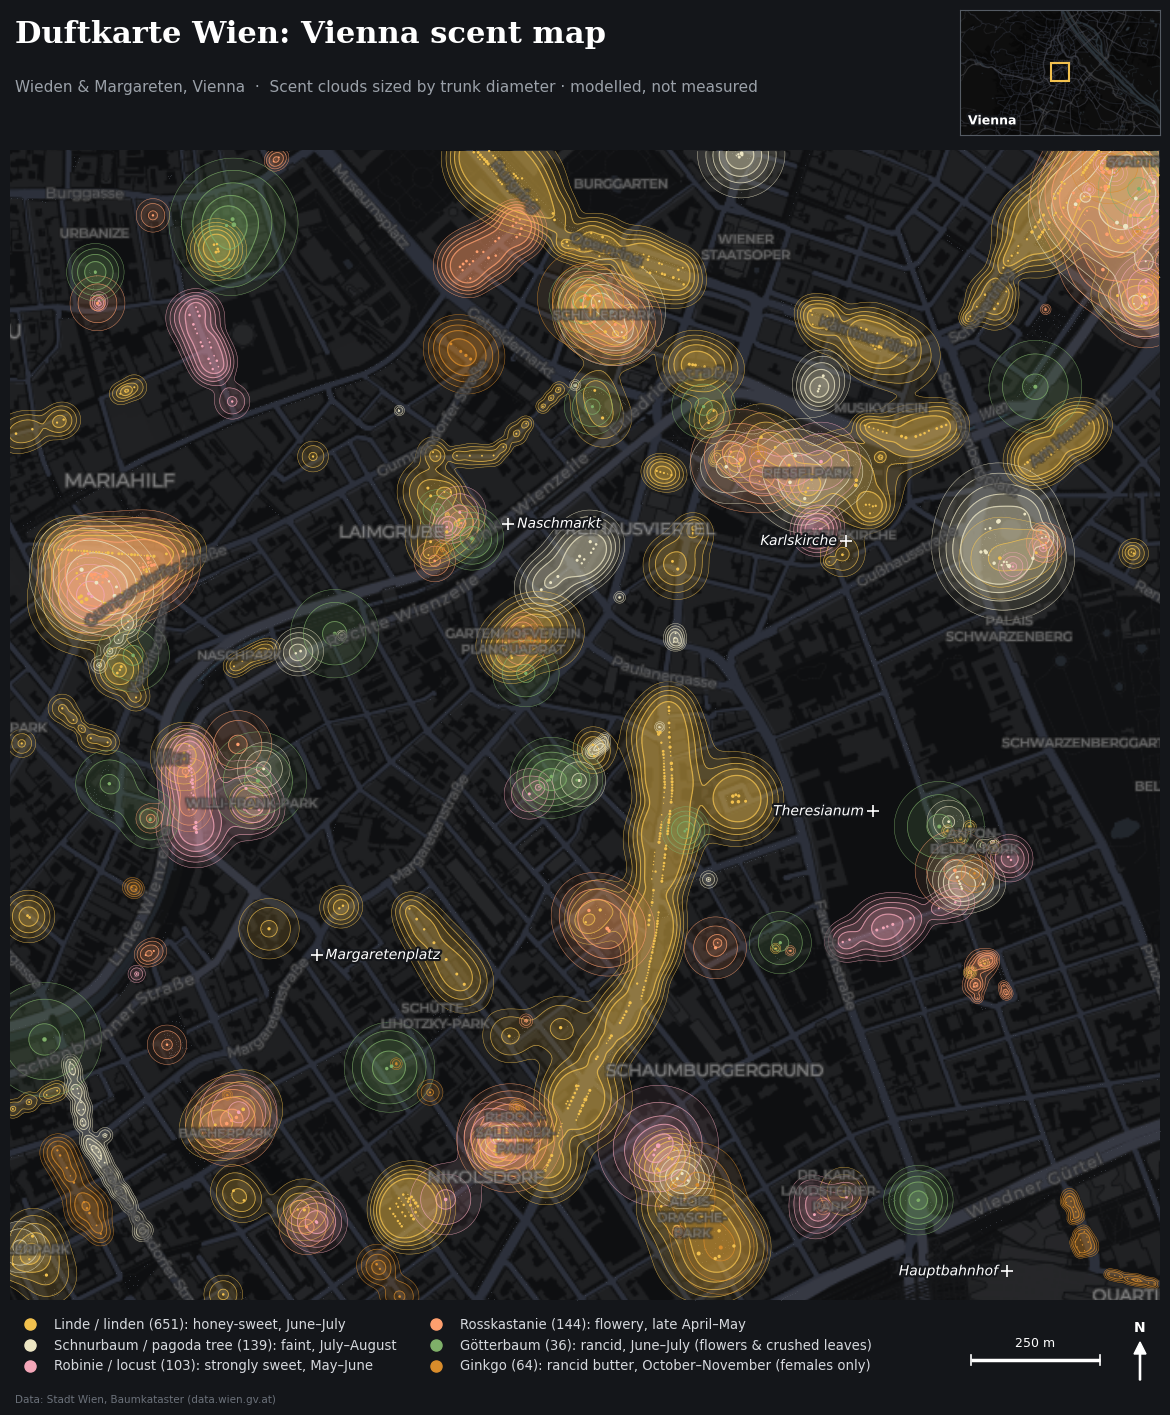

saved smellmap_vienna.png


In [105]:
# ── Section 5 · Draw the map ───────────────────────────────────────────────
# Built like stacked clear sheets. "zorder" sets the stacking order:
# higher numbers sit on top.
#   0 basemap · 1 grey tree dots · 2–4 scent clouds · 5 street names
#   6 landmarks · 7 scale bar · then inset, titles, legend, credits

import matplotlib.patheffects as pe          # for the dark outline ("halo") behind text
from matplotlib.patches import Rectangle     # for the yellow box in the inset
try:
    import contextily as ctx                 # fetches the basemap tiles
except ImportError:
    ctx = None                               # no contextily → map is drawn without tiles
    print("contextily not installed: drawing without a basemap (pip install contextily)")

BG = "#14161A"                                         # page background colour (near-black)
halo = [pe.withStroke(linewidth=3, foreground=BG)]     # dark outline that keeps white text readable

def carto(style):
    """Build the CARTO tile address for a style, with your API key attached."""
    return ("https://basemaps.cartocdn.com/rastertiles/" + style
            + "/{z}/{x}/{y}.png?key=" + CARTO_KEY)

if SHOW_BASEMAP and not CARTO_KEY:                     # warn early if the key is missing
    print("No CARTO_KEY set: CARTO tiles will carry an 'API KEY REQUIRED' watermark.")

def basemap(ax, source, **kw):
    """Add tiles to a map panel. If anything fails (no internet, bad key),
    print why and carry on: the map still draws, just without tiles."""
    if ctx is None:
        return
    try:
        ctx.add_basemap(ax, source=source, attribution=False, **kw)
    except Exception as e:
        print("basemap skipped:", e)

# ── Page layout (in inches) ──
# Header (title + inset) on top, map in the middle, footer (legend + credits) below.
Wfig, HEAD, FOOT = 12, 1.55, 1.15                      # page width, header height, footer height
Hmap = (Wfig - 0.5) * (ymax - ymin) / (xmax - xmin)    # map height follows the box's shape
Hfig = HEAD + Hmap + FOOT                              # total page height
fig = plt.figure(figsize=(Wfig, Hfig), facecolor=BG)
# The map panel: 0.25" margin each side, sitting just above the footer.
# fig.add_axes takes fractions of the page, hence the "/ Wfig" and "/ Hfig"
ax = fig.add_axes([0.25 / Wfig, FOOT / Hfig, (Wfig - 0.5) / Wfig, Hmap / Hfig])
ax.set_facecolor(BG)
ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)       # show exactly the BBOX
ax.set_aspect("equal")                                  # 1 m east = 1 m north (no squashing)

# 1. Dark street basemap without text, slightly see-through
if SHOW_BASEMAP:
    basemap(ax, carto("dark_nolabels"), alpha=0.55, zorder=0)

# Every tree in the box as a tiny grey dot: outlines the streets and shows
# where the non-fragrant trees are
ax.scatter(df.x, df.y, s=0.6, c="#4A505A", lw=0, alpha=0.6, zorder=1)

# 2. Scent clouds, one species at a time
handles = []                                            # collects legend entries
for i, (keys, label, col, note) in enumerate(SCENTS):
    sub = df[df.scent == i]                             # just this species' trees
    if sub.empty:
        continue                                        # species not in this area → skip
    # Build this species' sand piles (species never add to each other)
    f = scent_field(sub.x.values, sub.y.values, sub.dbh_cm.values, gx, gy, K)
    # Keep only ring levels this species actually reaches (e.g. a lone tree
    # never reaches 1.5). This is the fix for the earlier crash
    lvls = [lv for lv in LEVELS if lv < f.max()]
    if lvls:
        top = f.max() + 1                               # a ceiling above the highest point
        for k, lv in enumerate(lvls):
            # Soft fill from each level up to the top. Fills stack, and each
            # is a bit stronger (alpha 0.07, 0.10, 0.13...), so the cloud
            # glows brighter towards its centre
            ax.contourf(gx, gy, f, levels=[lv, top], colors=[col],
                        alpha=0.07 + 0.03 * k, zorder=2)
        # Thin ring lines on top, slightly thicker for inner rings
        ax.contour(gx, gy, f, levels=lvls, colors=[col],
                   linewidths=np.linspace(0.35, 0.9, len(LEVELS))[:len(lvls)],
                   alpha=0.75, zorder=3)
    # The fragrant trees themselves, dot size by trunk diameter
    ax.scatter(sub.x, sub.y, s=sub.dbh_cm * 0.1, c=col, lw=0, zorder=4)
    # Legend entry: coloured dot + "Label (count): scent note"
    handles.append(Line2D([], [], marker="o", ls="", color=col, markersize=8,
                          label=f"{label} ({len(sub):,}): {note}"))

# 3. Street and place names: a text-only tile layer placed ABOVE the clouds
if SHOW_BASEMAP and SHOW_TILE_LABELS:
    basemap(ax, carto("dark_only_labels"), alpha=0.85, zorder=5)

# 4. Hand-picked landmarks: a white + and an italic label
for name, lat, lon in LANDMARKS:
    x, y = to_merc(lat, lon)
    right_side = x > xmin + (xmax - xmin) * 0.7         # in the right 30% of the map?
    ax.plot(x, y, marker="+", color="white", ms=9, mew=1.2, zorder=6, clip_on=True)
    # Labels on the right side go LEFT of the + so they don't run off the edge.
    # clip_on=True hides anything outside the map
    ax.text(x, y, (name + "  ") if right_side else ("  " + name), color="white",
            fontsize=10, fontstyle="italic", va="center",
            ha="right" if right_side else "left", zorder=6, path_effects=halo, clip_on=True)

# 5. Scale bar and north arrow
# First pick a bar length that fits: try SCALE_M, then 1000, 500, 250, 200,
# 100, 50 m until it's short enough
in_per_unit = (Wfig - 0.5) / (xmax - xmin)              # page inches per map unit
max_in = 1.8 if SCALEBAR_IN_FOOTER else 0.22 * (Wfig - 0.5)   # longest allowed bar (inches)
for scale_m in [SCALE_M] + [m for m in (1000, 500, 250, 200, 100, 50) if m < SCALE_M]:
    if scale_m * K * in_per_unit <= max_in:
        break
L = scale_m * K                                          # bar length in map units (true metres)

if not SCALEBAR_IN_FOOTER:
    # Option A: inside the map, bottom-right corner
    x1 = xmax - (xmax - xmin) * 0.04; x0 = x1 - L        # bar's right and left ends
    yb = ymin + (ymax - ymin) * 0.03                     # just above the bottom edge
    ax.plot([x0, x1], [yb, yb], color="white", lw=2.5, solid_capstyle="butt", zorder=7, path_effects=halo)
    ax.text((x0 + x1) / 2, yb + (ymax - ymin) * 0.008, f"{scale_m:,} m", color="white",
            ha="center", va="bottom", fontsize=9, zorder=7, path_effects=halo)
    ax.annotate("N", xy=(x1, yb + (ymax - ymin) * 0.09), xytext=(x1, yb + (ymax - ymin) * 0.045),
                ha="center", va="center", color="white", fontsize=10, fontweight="bold", zorder=7,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=1.2))
else:
    # Option B (Vienna): in the footer, right of the legend.
    # Drawn on the page rather than the map, so its length is converted from
    # map units to inches to stay at the map's true scale
    bar_in = L * in_per_unit                             # bar length in inches
    fx1 = (Wfig - 0.85) / Wfig                           # right end, leaving room for the arrow
    fx0 = fx1 - bar_in / Wfig                            # left end
    fy = 0.55 / Hfig                                     # height on the page (in the footer)
    fig.add_artist(Line2D([fx0, fx1], [fy, fy], transform=fig.transFigure,
                          color="white", lw=2.5, solid_capstyle="butt"))
    for fx in (fx0, fx1):                                # small ticks at both ends
        fig.add_artist(Line2D([fx, fx], [fy - 0.05 / Hfig, fy + 0.05 / Hfig],
                              transform=fig.transFigure, color="white", lw=1.2))
    fig.text((fx0 + fx1) / 2, fy + 0.1 / Hfig, f"{scale_m:,} m", color="white",
             ha="center", va="bottom", fontsize=9)
    fax = (Wfig - 0.45) / Wfig                           # north arrow's position
    fig.text(fax, fy + 0.32 / Hfig, "N", color="white", ha="center", va="center",
             fontsize=10, fontweight="bold")
    fig.patches.append(plt.matplotlib.patches.FancyArrow(
        fax, fy - 0.2 / Hfig, 0, 0.38 / Hfig, width=0.012 / Wfig, head_width=0.12 / Wfig,
        head_length=0.12 / Hfig, length_includes_head=True, color="white",
        transform=fig.transFigure, figure=fig))
ax.axis("off")                                           # hide the map's axis ticks and frame

# 6. Locator inset (top-right): where your area sits in the city
IN_H = 1.25                                              # inset height (inches), fits the header
ins = fig.add_axes([(Wfig - 0.25 - IN_H * 1.6) / Wfig, (Hfig - 0.15 - IN_H) / Hfig,
                    IN_H * 1.6 / Wfig, IN_H / Hfig])     # 1.6 : 1 wide, top-right corner
cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2            # centre of your area
half = max(xmax - xmin, ymax - ymin) * INSET_ZOOM_OUT / 2   # zoomed out INSET_ZOOM_OUT times
ins.set_xlim(cx - half * 1.6, cx + half * 1.6); ins.set_ylim(cy - half, cy + half)
ins.set_facecolor("#22262C")
if SHOW_BASEMAP:
    basemap(ins, carto("dark_all"), zorder=0)            # tiles with labels, for a city overview
ins.add_patch(Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False,
                        ec="#F2C14E", lw=1.5, zorder=3)) # yellow box = your map's area
ins.set_xticks([]); ins.set_yticks([])                   # no axis numbers
for s_ in ins.spines.values():
    s_.set_color("#555B63")                              # thin grey frame
ins.text(0.04, 0.06, CITY, transform=ins.transAxes, ha="left", va="bottom",
         color="white", fontsize=9, fontweight="bold", zorder=4, path_effects=halo)

# 7. Text: title, subtitle, legend, credits
# Positions are in inches from the page edges, converted to page fractions
fig.text(0.3 / Wfig, 1 - 0.25 / Hfig, f"Duftkarte Wien: Vienna scent map", color="white",
         fontsize=22, fontweight="bold", va="top", family="serif")
fig.text(0.3 / Wfig, 1 - 0.85 / Hfig, f"{SUBTITLE}  ·  Scent clouds sized by trunk diameter · modelled, not measured",
         color="#9AA0A8", fontsize=11, va="top")
fig.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.2 / Wfig, 0.3 / Hfig),
           frameon=False, fontsize=9.5, labelcolor="#D6D9DE", ncol=2)   # 2-column legend
fig.text(0.3 / Wfig, 0.1 / Hfig, f"Data: {CREDIT}",
         color="#6B717A", fontsize=7.5, ha="left", va="bottom")

# Save the PNG (250 dpi, about 3000 px wide) and show it in the notebook
fig.savefig(OUT, dpi=250, facecolor=BG)
plt.show()
print("saved", OUT)

## Tweaks

- **`SIGMA_M_PER_CM`**: how far scent carries per cm of trunk. Raise it for dreamy merged clouds, lower it for crisp rings.
- **`LEVELS`**: contour thresholds. Fewer levels look calmer.
- **Landmarks:** if you change `BBOX`, update `LANDMARKS` too (anything outside the box is still drawn, so remove those).
- **`BBOX`**: keep it about 2 km across. A whole city turns to mush.
- **`SCENTS`**: add, remove or recolour species. Matching uses lowercase substrings of the Latin name.
- **Real-world check:** street-tree registers record trunk size, not flowering or sex. Scent strength is a guess.